# Лабораторна робота 3

ResNet-18: scratch, frozen, unfreeze. Сім запусків за бюджетом $8\cdot38=304$ кроки кожен. Код навчання та аналізу спільний зі скриптами `train.py`, `experiment.py` і `analyze.py`.

In [1]:
from pathlib import Path
import csv
import json
from IPython.display import Image, Markdown, display

from experiment import CLASSES
from train import train
from analyze import analyze

data = Path('../data/intel-image-classification')
out = Path('.')

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

def show_table(rows):
    headers = list(rows[0])
    def value(v):
        if isinstance(v, float):
            return f'{v:.6f}'
        return str(v)
    lines = ['| ' + ' | '.join(headers) + ' |', '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(value(row[h]) for h in headers) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))

## Повторне навчання

Результати семи запусків уже збережені. Для нового експерименту встанови шлях до набору в попередній клітинці та зміни `RUN_TRAINING` на `True`. Нова тека має бути порожньою. Навчання виконує контроль поділу й BatchNorm, усі сім запусків та вибирає модель лише за validation; test не завантажується.

In [2]:
RUN_TRAINING = False
if RUN_TRAINING:
    out = Path('reproduced')
    selection = train(data, out, 'auto')
    print(selection)

## Перевірки до навчання

Прогноз досліду з BN: `requires_grad=False` блокує градієнти параметрів, але не змінює режим роботи BatchNorm. У помилковому frozen із `model.train()` параметри кістяка лишаться сталими, а ковзні статистики зміняться.

Початкова втрата порівнюється з

$$
L_{\mathrm{uniform}}=-\log\frac{1}{6}=\ln6\approx1.792.
$$

Початкові втрати scratch 2.047949 і frozen 1.924237 не зобов'язані дорівнювати $\ln6$: випадкова голова дає нерівномірні ймовірності. Перевірочні моделі відкидаються, бо BN навіть під `no_grad()` може оновити буфери. У правильному frozen зміни `layer1.0.bn1` нульові; у помилковому — 0.09282255 для `running_mean` і 0.12034309 для `running_var`. Прогноз підтвердився; зниження train-loss саме по собі помилку не виявляє. Для розмороженого `layer4` оновлення BN правильне.

| label | part | count | filename_sum | passed |
| --- | --- | --- | --- | --- |
| buildings | train | 200 | 1996761 | True |
| forest | train | 200 | 2032625 | True |
| glacier | train | 200 | 2183923 | True |
| mountain | train | 200 | 1950345 | True |
| sea | train | 200 | 1987613 | True |
| street | train | 200 | 1841817 | True |
| buildings | validation | 218 | 4837323 | True |
| forest | validation | 237 | 5276962 | True |
| glacier | validation | 276 | 6135652 | True |
| mountain | validation | 262 | 5789535 | True |
| sea | validation | 255 | 5655068 | True |
| street | validation | 250 | 5541845 | True |
| buildings | test | 219 | 4837559 | True |
| forest | test | 237 | 5291326 | True |
| glacier | test | 277 | 6157250 | True |
| mountain | test | 263 | 5849765 | True |
| sea | test | 255 | 5668011 | True |
| street | test | 251 | 5547533 | True |

Initial losses: {'scratch': 2.0479493141174316, 'frozen': 1.9242374897003174} ln(6): 1.791759469228055


| regime | total | trainable | optimizer_groups |
| --- | --- | --- | --- |
| scratch | 11179590 | 11179590 | [{'name': 'all', 'numel': 11179590, 'lr': 0.003, 'weight_decay': 0.0001}] |
| frozen | 11179590 | 3078 | [{'name': 'fc', 'numel': 3078, 'lr': 0.003, 'weight_decay': 0.0001}] |
| unfreeze | 11179590 | 8396806 | [{'name': 'fc', 'numel': 3078, 'lr': 0.003, 'weight_decay': 0.0001}, {'name': 'layer4', 'numel': 8393728, 'lr': 0.0003, 'weight_decay': 0.0001}] |

| regime | module | parameters_changed | bn_statistics_changed | passed |
| --- | --- | --- | --- | --- |
| frozen | conv1 | False | None | True |
| frozen | bn1 | False | False | True |
| frozen | layer1 | False | False | True |
| frozen | layer2 | False | False | True |
| frozen | layer3 | False | False | True |
| frozen | layer4 | False | False | True |
| frozen | fc | True | None | True |
| unfreeze | conv1 | False | None | True |
| unfreeze | bn1 | False | False | True |
| unfreeze | layer1 | False | False | True |
| unfreeze | layer2 | False | False | True |
| unfreeze | layer3 | False | False | True |
| unfreeze | layer4 | True | True | True |
| unfreeze | fc | True | None | True |
| frozen_bug | conv1 | False | None | True |
| frozen_bug | bn1 | False | True | True |
| frozen_bug | layer1 | False | True | True |
| frozen_bug | layer2 | False | True | True |
| frozen_bug | layer3 | False | True | True |
| frozen_bug | layer4 | False | True | True |
| frozen_bug | fc | True | None | True |

BN bug maximum changes: {'running_mean': 0.09282255172729492, 'running_var': 0.12034308910369873}


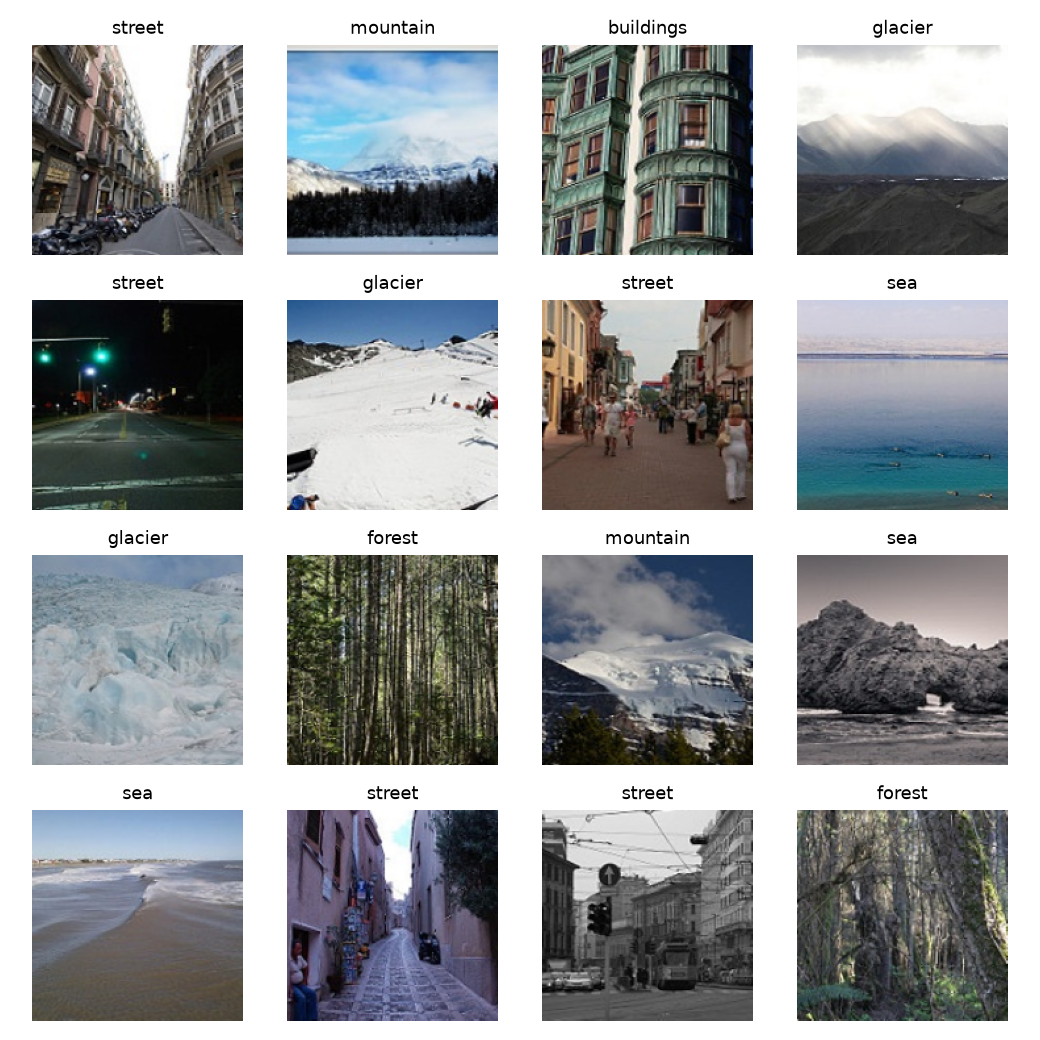

In [3]:
checks = read_json(out / 'results/preflight.json')
with (out / 'results/split_control.csv').open(encoding='utf-8', newline='') as stream:
    show_table(list(csv.DictReader(stream)))
print('Initial losses:', checks['initial_losses'], 'ln(6):', checks['uniform_loss'])
show_table([{'regime': row['regime'], 'total': row['total'], 'trainable': row['trainable'],
             'optimizer_groups': str(row['groups'])} for row in checks['parameter_checks']])
mode_rows = []
for regime, check in [*checks['mode_checks'].items(), ('frozen_bug', checks['bn_bug'])]:
    for row in check['modules']:
        mode_rows.append({'regime': regime, **row})
show_table(mode_rows)
print('BN bug maximum changes:', checks['bn_bug']['layer1_bn1_max_changes'])
assert checks['all_passed']
display(Image(filename=str(out / 'results/batch.png'), width=700))

## Аналіз і test

Команда аналізу перевіряє SHA-256 поділу у всіх журналах, правило вибору та відповідність ваг вибраному запуску. Лише після цього вона обчислює test на CPU.

За замовчуванням клітинка читає вже отриманий звіт. Для відтворення тестової оцінки встанови `RUN_ANALYSIS=True`; результат не використовується для повторного вибору моделі.

| run | regime | seed | train_loss | validation_macro_f1 | seconds |
| --- | --- | --- | --- | --- | --- |
| 1 | scratch | 1 | 1.010167 | 0.499898 | 86.741310 |
| 2 | frozen | 1 | 0.165472 | 0.884201 | 77.772118 |
| 3 | frozen | 2 | 0.175659 | 0.878500 | 77.583409 |
| 4 | frozen | 3 | 0.189572 | 0.888596 | 77.203447 |
| 5 | unfreeze | 1 | 0.063509 | 0.865052 | 76.970860 |
| 6 | unfreeze | 2 | 0.108795 | 0.876207 | 73.729735 |
| 7 | unfreeze | 3 | 0.068530 | 0.896838 | 74.610706 |

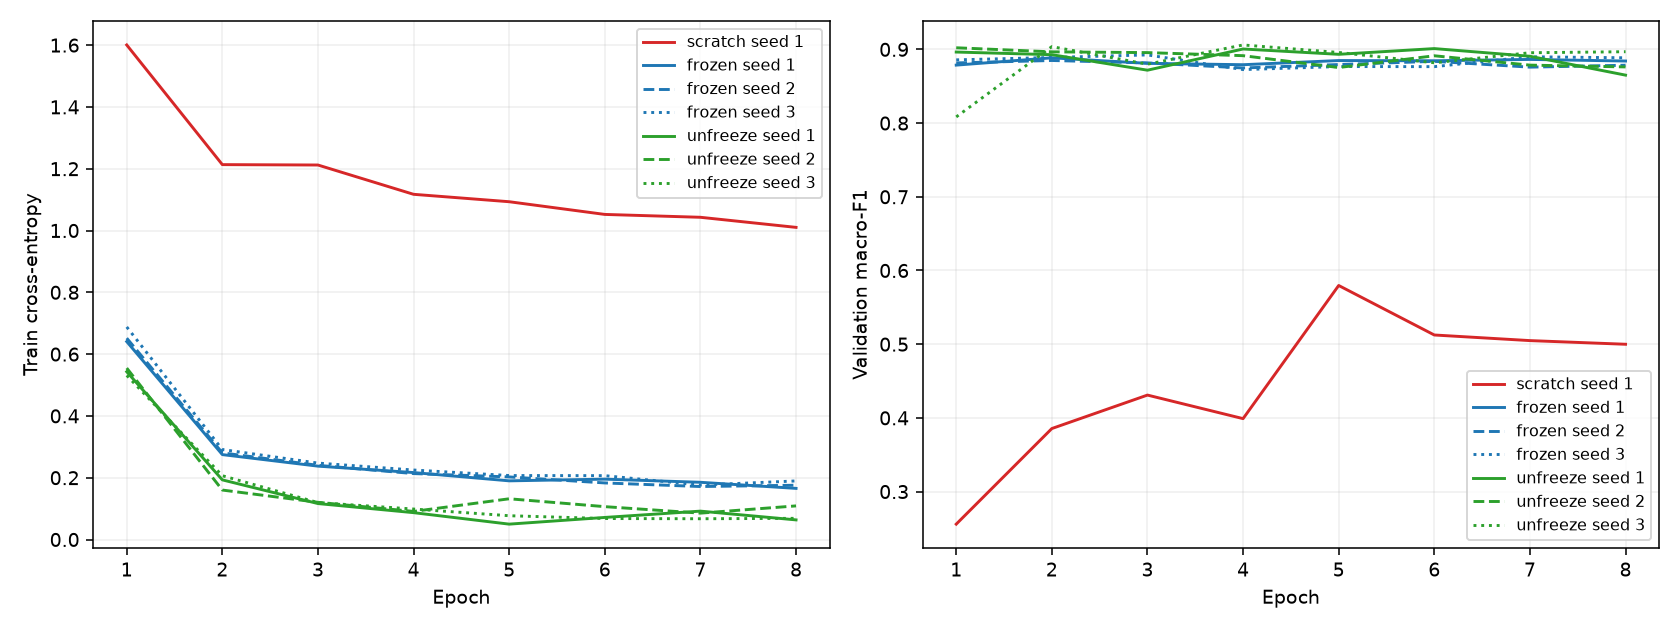

In [4]:
RUN_ANALYSIS = False
report = analyze(data, out) if RUN_ANALYSIS else read_json(out / 'results/analysis.json')
show_table(report['runs'])
display(Image(filename=str(out / 'results/training_curves.png'), width=1000))

## Розклад ефектів

$$
\begin{aligned}
\overline F_r&=\frac{1}{3}\sum_{s=1}^{3}F_{r,s},&
R_r&=\max_s F_{r,s}-\min_s F_{r,s},\\
R&=\max(R_{\mathrm{frozen}},R_{\mathrm{unfreeze}}),\\
\Delta_{\mathrm{pre}}&=\overline F_{\mathrm{frozen}}-F_{\mathrm{scratch},1},\\
\Delta_{\mathrm{unf}}&=\overline F_{\mathrm{unfreeze}}-\overline F_{\mathrm{frozen}}.
\end{aligned}
$$

За $\lvert\Delta\rvert\le R$ різниця не відрізняється від розкиду. За $\lvert\Delta\rvert>R$ ефект вартий подальшої перевірки, але не доведений.

Сума ефектів — повний виграш трансферу:

$$
\Delta_{\mathrm{pre}}+\Delta_{\mathrm{unf}}=\overline F_{\mathrm{unfreeze}}-F_{\mathrm{scratch},1}.
$$

| quantity | value |
| --- | --- |
| mean_frozen | 0.883766 |
| range_frozen | 0.010095 |
| mean_unfreeze | 0.879365 |
| range_unfreeze | 0.031786 |
| R | 0.031786 |
| delta_pre | 0.383868 |
| delta_unf | -0.004400 |
| total_gain | 0.379467 |
| pre_exceeds_noise | True |
| unfreeze_exceeds_noise | False |

Selected: {'regime': 'frozen', 'seed': 3, 'validation_macro_f1': 0.8885955696095422}
Test macro-F1: 0.8912105506575774
Test accuracy: 0.8894806924101198
Accuracy standard error: 0.008090071763894462


| true_class | buildings | forest | glacier | mountain | sea | street |
| --- | --- | --- | --- | --- | --- | --- |
| buildings | 187 | 2 | 0 | 1 | 2 | 27 |
| forest | 0 | 237 | 0 | 0 | 0 | 0 |
| glacier | 0 | 1 | 215 | 49 | 10 | 2 |
| mountain | 1 | 0 | 40 | 212 | 10 | 0 |
| sea | 2 | 1 | 1 | 1 | 250 | 0 |
| street | 13 | 0 | 0 | 2 | 1 | 235 |

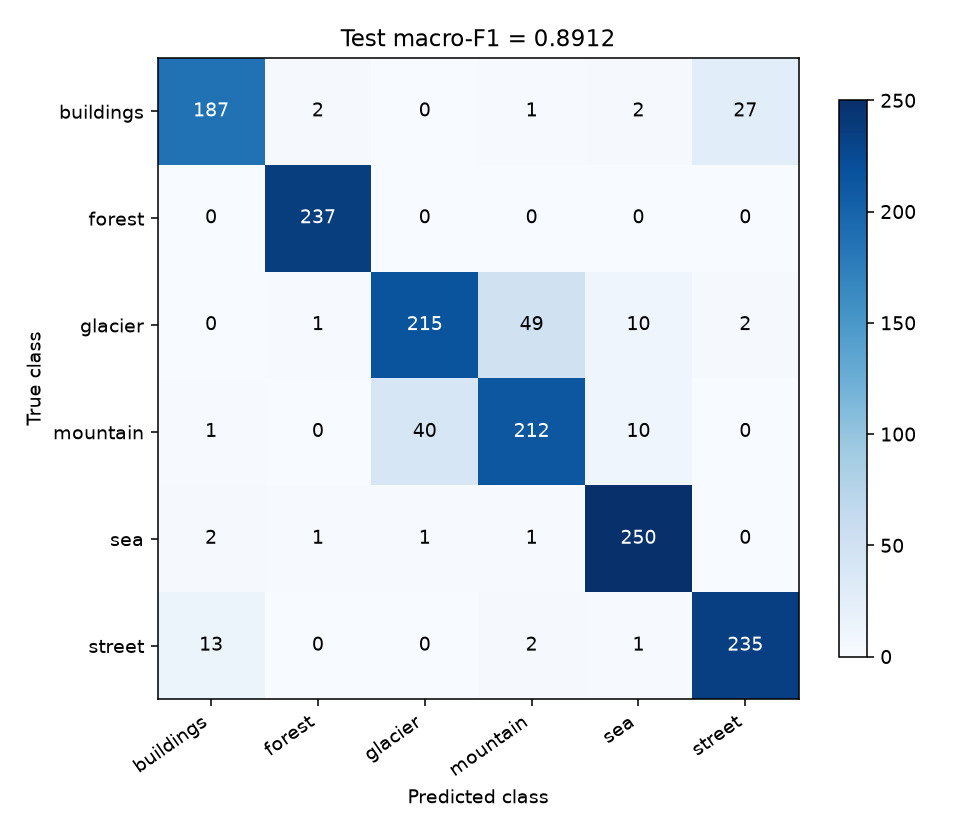

In [5]:
show_table([{'quantity': key, 'value': value} for key, value in report['effects'].items()])
print('Selected:', report['selected'])
print('Test macro-F1:', report['test']['macro_f1'])
print('Test accuracy:', report['test']['accuracy'])
print('Accuracy standard error:', report['test']['accuracy_standard_error'])
matrix = report['test']['confusion_matrix']
show_table([{'true_class': name, **dict(zip(CLASSES, matrix[i]))} for i, name in enumerate(CLASSES)])
display(Image(filename=str(out / 'results/confusion_matrix.png'), width=650))

Для збережених запусків середнє frozen (0.8837657142) вище за unfreeze (0.8793653627). Тому обрано frozen, а всередині нього — seed 3 (0.8885955696), а не окремий найкращий результат серед усіх семи. Різниця середніх менша за $R=0.0317862770$, тож вибір між двома режимами визначив шум.

Test macro-F1 0.8912105507 виявилася вищою за validation на 0.0026149810. Вибір найкращого зерна створює оптимістичне зміщення validation у середньому, але шум конкретних двох вибірок може його приховати або змінити знак різниці.

$$
\mathrm{SE}_{\mathrm{accuracy}}=\sqrt{\frac{p(1-p)}{1502}}=0.0080900718,
\qquad p=0.8894806924.
$$

Це порядок шуму accuracy, а не стандартна похибка macro-F1 і не тест значущості різниці validation/test.

## П'ять характерних помилок

Пари класів упорядковані за спаданням частоти помилок, за нічиєї - за індексами справжнього та передбаченого класу. Файл усередині кожної пари вибирається першим за рядковим сортуванням імен.

| file | true_class | predicted_class | probability | pair_count |
| --- | --- | --- | --- | --- |
| 20179.jpg | glacier | mountain | 0.877206 | 49 |
| 20116.jpg | mountain | glacier | 0.601541 | 40 |
| 20083.jpg | buildings | street | 0.593569 | 27 |
| 20353.jpg | street | buildings | 0.844027 | 13 |
| 20243.jpg | glacier | sea | 0.806998 | 10 |

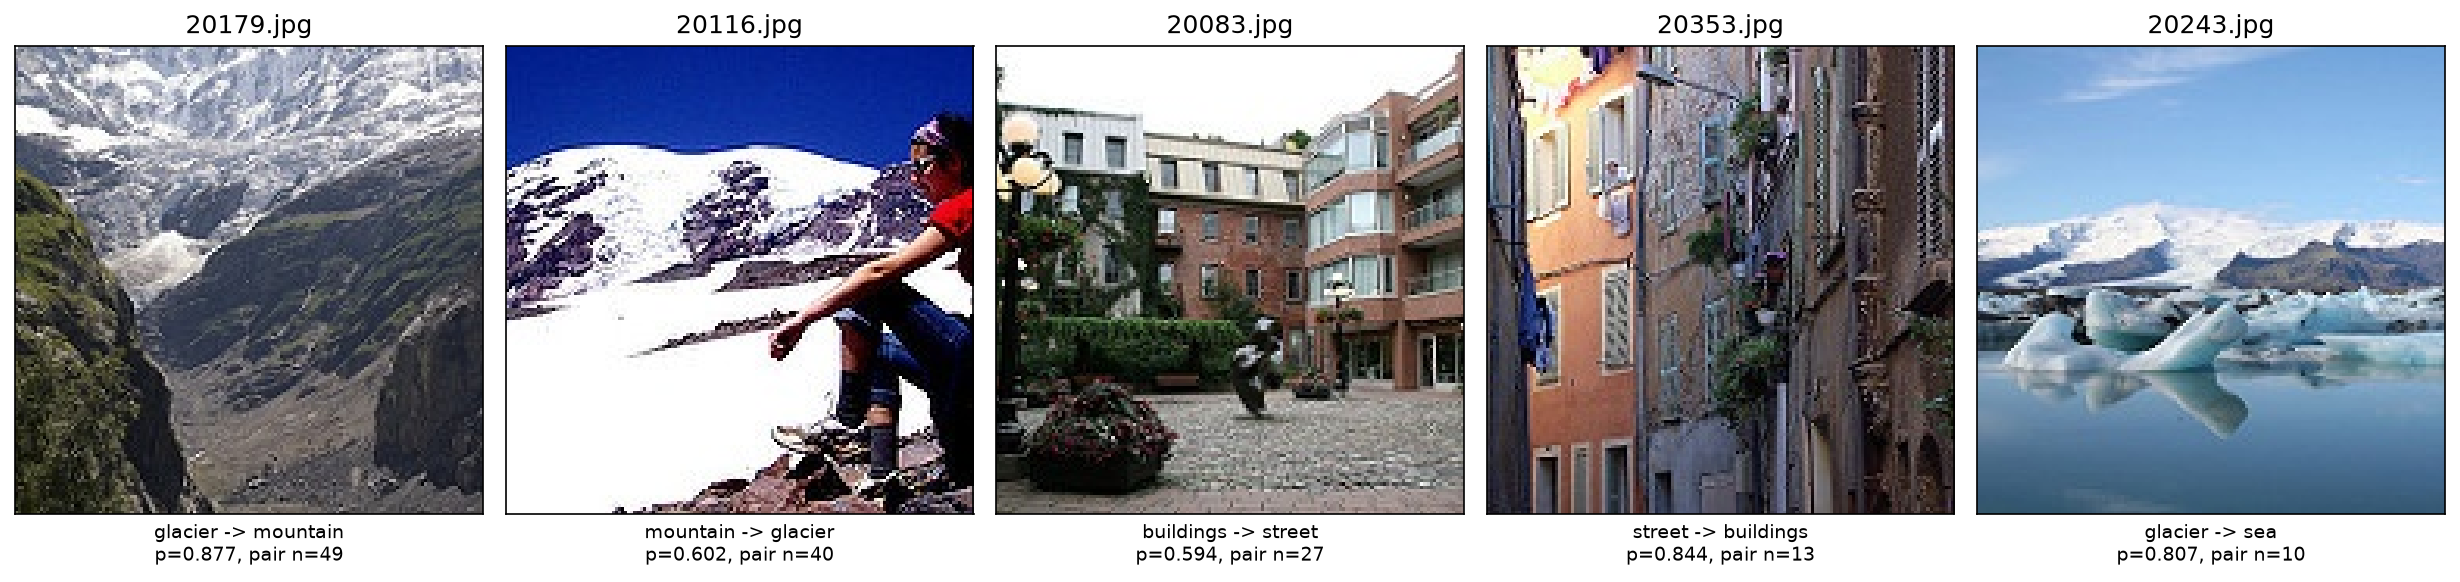

In [6]:
show_table(report['errors'])
display(Image(filename=str(out / 'results/errors.png'), width=1100))

Для наведених збережених результатів:

- 20179.jpg — сцена містить обидва класи: гірські схили оточують льодовикову долину.
- 20116.jpg — сцена містить обидва класи: гірський рельєф і велике снігово-льодове поле.
- 20083.jpg — сцена містить обидва класи: будівлі та вимощений міський простір.
- 20353.jpg — ймовірна помилка розмітки: домінують фасади будівель, сама вулиця майже не видима.
- 20243.jpg — помилка моделі на однозначному зображенні: помітні великі крижини й льодовикове тло.

Це візуальні інтерпретації, не підтверджені виправлення міток. Плутанина glacier ↔ mountain — властивість набору; мітки не змінюються.

## Висновок

За бюджету **304 кроки** попередні ImageNet-ознаки дали додатний ефект **+38.3868 пункту macro-F1**: frozen 0.8837657142 проти scratch 0.4998978672. Це більше за розкид $R$, або 3.1786 пункту: ефект вартий перевірки, але не доведений.

Розморожування дало виміряну різницю **−0.4400 пункту**: unfreeze 0.8793653627 проти frozen 0.8837657142. Її модуль менший за $R$, тому різниця не відрізняється від шуму, результату щодо користі чи шкоди unfreeze немає. Повний виграш трансферу — +37.9467 пункту. Із довшим навчанням scratch міг би скоротити відставання.

У scratch зерно змінює весь випадковий кістяк і голову, у frozen та unfreeze — голову; в усіх режимах також змінюються перемішування й аугментації. У unfreeze вони впливають ще й на адаптацію layer4 та BN, що може збільшувати розкид. $R$ із шести трансферних запусків не оцінює варіативність єдиного scratch-запуску: його loss знижується, а macro-F1 зростає від 0.255826 до 0.499898, але інших scratch-зерен немає.

Кількість кроків однакова, час — ні: scratch 86.74 с, frozen 77.20–77.77 с, unfreeze 73.73–76.97 с. Для нової задачі з 200 зображеннями на клас я почав би з **frozen**: менший розкид, зіставний час і відсутність встановленого виграшу від unfreeze. Після test модель і налаштування не змінювалися.

Повний звіт, команди, версії та джерела — у [README](README.md). Під час підготовки коду використовувався OpenAI ChatGPT.